# Practicum 1
- Basic parsing and iteration of Structure objects in BioPython (PDB module)
- Save selected residues into a new PDB file

### Biopython cookbook
https://biopython.org/DIST/docs/tutorial/Tutorial.html

### Bio.PDB module FAQ
https://biopython.org/wiki/The_Biopython_Structural_Bioinformatics_FAQ


In [1]:
!pip install biopython

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 27.1 MB/s eta 0:00:00


In [37]:
from Bio.PDB import PDBList, is_aa, PDBIO, NeighborSearch, calc_angle, calc_dihedral, PPBuilder
from Bio.PDB.PDBParser import PDBParser
from Bio.SeqUtils import IUPACData
from Bio.PDB.PDBIO import Select
from Bio.SeqIO.PdbIO import PdbSeqresIterator
from Bio.PDB.MMCIFParser import MMCIFParser

import math
import copy
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as mplcolors
from matplotlib.ticker import (MultipleLocator, AutoMinorLocator)
import scipy.signal

In [3]:
# Mount your personal Google drive
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [4]:
# Set path to a fodler for input/output data
# Change here according to your setup
import os
path = 'drive/MyDrive/Colab Notebooks/Structural Biology/data'
if os.path.exists(path +'/figures') is False:
  os.mkdir(path +'/figures')

# Parsing

In [5]:
# Input
pdb_id = '1lkk' # Other interesting PDBs 1byi 3k8y 1nww

In [6]:
# Fetch a PDB file from the website to the current dir
# Question: how do you download structures from the PDB?
pdbl = PDBList()
pdbl.retrieve_pdb_file(pdb_id, pdir=path + "/pdb", file_format='pdb')  # Will save a pdbXXXX.ent file

Structure exists: 'drive/MyDrive/Colab Notebooks/Structural Biology/data/pdb/pdb1lkk.ent' 


'drive/MyDrive/Colab Notebooks/Structural Biology/data/pdb/pdb1lkk.ent'

In [7]:
# Get the SEQRES using SeqIO
# It finds and parse all SEQRES fields inside a PDB file and create SeqRecord objects
with open(path + "/pdb/pdb{}.ent".format(pdb_id)) as f:
  seq_records = (PdbSeqresIterator(f))
  for seq_record in seq_records:
    print(seq_record)


# Print SeqRecord methods and attributes
#print("\n".join([ele for ele in dir(seq_record) if ele[0] != '_']))

#Выбираем только тот сиквенс с белка, который кристаллизовали!!
#Не все residues всегда прям кристаллизуют

#Seq_records - это особый тип данных: https://biopython.org/wiki/SeqRecord

ID: 1LKK:A
Name: 1LKK:A
Description: UNP:P06239 LCK_HUMAN
Database cross-references: UNP:P06239, UNP:LCK_HUMAN
Number of features: 0
/chain=A
/molecule_type=protein
Seq('LEPEPWFFKNLSRKDAERQLLAPGNTHGSFLIRESESTAGSFSLSVRDFDQNQG...CQT')
ID: 1LKK:B
Name: 1LKK:B
Description: PDB:1LKK 1LKK
Database cross-references: PDB:1LKK, PDB:1LKK
Number of features: 0
/chain=B
/molecule_type=protein
Seq('XYEEI')


In [8]:
# Create the structure object
pdb_id = '1lkk'
structure = PDBParser(QUIET=True).get_structure(pdb_id, path + "/pdb/pdb{}.ent".format(pdb_id))

# Iterate the structure
for model in structure:
  for chain in model:
    for residue in chain:

      # The "is_aa" function checks whether a residue is an amino acid and not a modified residue, HETATM, ligand, ion, etc.
      if is_aa(residue):

        # "residue.id" is a tuple that contains: i) hetero_flag, ii) position (residue index), iii) insertion_code
        # "IUPACData" is a package to conver residues names from 3 letters to 1 letter
        print("model {} chain {} residue_id {} resname {} resname_3to1 {}".format(
            model.id, chain.id, residue.id, residue.get_resname(),
            IUPACData.protein_letters_3to1.get(residue.get_resname().capitalize())))

        # Print all atoms of a residue
        for atom in residue:
            print("atom {} {} {}".format(atom.id, atom.get_bfactor(), atom.get_coord()))

        break
      break
    break
  break

#PDBпарсер формирует свою стр-ру данных для корректной визуализации

model 0 chain A residue_id (' ', 122, ' ') resname LEU resname_3to1 L
atom N 20.16 [49.672  7.391 11.364]
atom CA 20.25 [50.03   7.561 12.734]
atom C 16.62 [48.886  7.48  13.726]
atom O 15.23 [47.816  8.07  13.517]
atom CB 21.98 [51.116  8.488 13.074]
atom CG 22.5 [51.381  8.978 14.477]
atom CD1 23.9 [52.229  8.017 15.285]
atom CD2 26.42 [51.959 10.377 14.502]
atom H1 30.24 [48.995  6.786 11.3  ]
atom H2 30.24 [49.399  8.188 11.02 ]
atom H3 30.24 [50.392  7.09  10.897]
atom HA 24.3 [50.481  6.686 12.91 ]
atom HB2 26.37 [51.955  8.066 12.76 ]
atom HB3 26.37 [50.982  9.295 12.515]
atom HG 27.0 [50.493  9.028 14.933]
atom HD11 35.85 [51.771  7.153 15.351]
atom HD12 35.85 [53.095  7.895 14.844]
atom HD13 35.85 [52.368  8.382 16.184]
atom HD21 39.63 [52.806 10.39  14.01 ]
atom HD22 39.63 [51.327 10.999 14.083]
atom HD23 39.63 [52.116 10.649 15.431]


# Cut and save a PDB

For example you may want to extract a fragment corresponding to an important part of the protein (domain).

We use a sentinel mechanism to know when to start and finish parsing since the PDB numbering is not guaranteed to be continuous and residue numbers can contain insertion codes, i.e. multiple residues can have the same numbers and different insertion codes.

In [9]:
# # Extract a fragment (domain) excluding hetero and water atoms
# # Start end positions of a domain identified in PDB 1CU4
# pdb_id = '1lkk'
# structure = PDBParser(QUIET=True).get_structure(pdb_id, path + "/pdb/pdb{}.ent".format(pdb_id))

# domain_start = (" ", 122, " ")
# domain_end = (" ", 226, " ")

# domain_residues = []
# start_flag = False

# # Iterate residues of specific chain (L) and model (0)
# for residue in structure[0]['A'].get_residues():  # Model 0, chain A
#     if residue.id[0] == " ":
#       # Exclude hetero and water atoms
#         # print(residue.id)
#         # Get starting position, a piori I don't know where is the first residue
#         if residue.id == domain_start:
#             start_flag = True

#         if start_flag:
#             domain_residues.append(residue)
#             # print(residue.id)

#         # Get ending position
#         if residue.id == domain_end:
#             break

In [10]:
# for residue in structure[0]['A']:
#     if residue.id[0] == " ":
#         print(residue.id)

In [11]:
from Bio.PDB import Select as PDBSelect

class DomainSelect(PDBSelect):
    def __init__(self, chain_ids=None, residues=None):
        self.chain_ids = chain_ids
        self.residues = residues

    def accept_chain(self, chain):
        return self.chain_ids is None or chain.id in self.chain_ids

    def accept_residue(self, residue):
        return self.residues is None or residue in self.residues

    def accept_atom(self, atom):
        return (not atom.is_disordered()) or atom.get_altloc() == "A"

In [12]:
pdb_id = '1lkk'
structure = PDBParser(QUIET=True).get_structure(
    pdb_id, path + f"/pdb/pdb{pdb_id}.ent"
)

chain_id = 'A'
start_resseq = 122
end_resseq = 226

domain_residues = []

for residue in structure[0][chain_id]:
    if residue.id[0] != " ":
        continue
    if start_resseq <= residue.id[1] <= end_resseq:
        domain_residues.append(residue)

print("Number of selected residues:", len(domain_residues))
print("First few:", [r.id for r in domain_residues[:10]])

Number of selected residues: 105
First few: [(' ', 122, ' '), (' ', 123, ' '), (' ', 124, ' '), (' ', 125, ' '), (' ', 126, ' '), (' ', 127, ' '), (' ', 128, ' '), (' ', 129, ' '), (' ', 130, ' '), (' ', 131, ' ')]


In [13]:
# Save a PDB file containing only a list of selected residues
io = PDBIO()
io.set_structure(structure[0])
io.save(path + "/pdb/pdb{}_cut.ent".format(pdb_id), select=DomainSelect(residues=domain_residues))

# Ex.7: Heatmap of distances (CB [or CA if missing] with residue indexes along axes)

In [23]:
def get_distance_matrix(residues, seq_sep=5):
  """
  Calculate a distance matrix considering only
  CA atoms and a minimum sequence separation.
  Return a Numpy array
  """
  distances = []

  for i, residue1 in enumerate(residues):
      row = []
      for j, residue2 in enumerate(residues):

          if abs(i - j) >= seq_sep:

              if "CB" in residue1:
                  atom1 = residue1["CB"]
              else:
                  atom1 = residue1["CA"]

              if "CB" in residue2:
                  atom2 = residue2["CB"]
              else:
                  atom2 = residue2["CA"]

              row.append(atom1 - atom2)

          else:
              row.append(np.nan)

      distances.append(row)

  return np.array(distances, dtype=float)

In [24]:
# Input
pdb_id = '1lkk'
sequence_separation = 6

# # Fetch a PDB file to the current dir
pdbl = PDBList()
pdbl.retrieve_pdb_file(pdb_id, pdir=path + "/pdb", file_format='pdb')
structure = PDBParser(QUIET=True).get_structure(pdb_id, path + "/pdb/pdb{}.ent".format(pdb_id))

# select chain A of first model (0) and exclude hetero and water groups
selected_residues = [residue for residue in structure[0]['A'] if residue.id[0] == " "]
residue_ids = [res.id[1] for res in selected_residues]

# Used sequence separations are: 5 (short range), 12, 24 (long range)
dist_matrix = get_distance_matrix(selected_residues, sequence_separation)
dist_matrix

Structure exists: 'drive/MyDrive/Colab Notebooks/Structural Biology/data/pdb/pdb1lkk.ent' 


array([[        nan,         nan,         nan, ..., 18.88153267,
        21.03225899, 17.73386383],
       [        nan,         nan,         nan, ..., 16.67350769,
        17.99810982, 15.80208969],
       [        nan,         nan,         nan, ..., 11.62862968,
        14.40122128, 11.71240425],
       ...,
       [18.88153267, 16.67350769, 11.62862968, ...,         nan,
                nan,         nan],
       [21.03225899, 17.99810982, 14.40122128, ...,         nan,
                nan,         nan],
       [17.73386383, 15.80208969, 11.71240425, ...,         nan,
                nan,         nan]])

/tmp/ipykernel_20415/1228092246.py:1: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  current_cmap = copy.copy(matplotlib.cm.get_cmap())


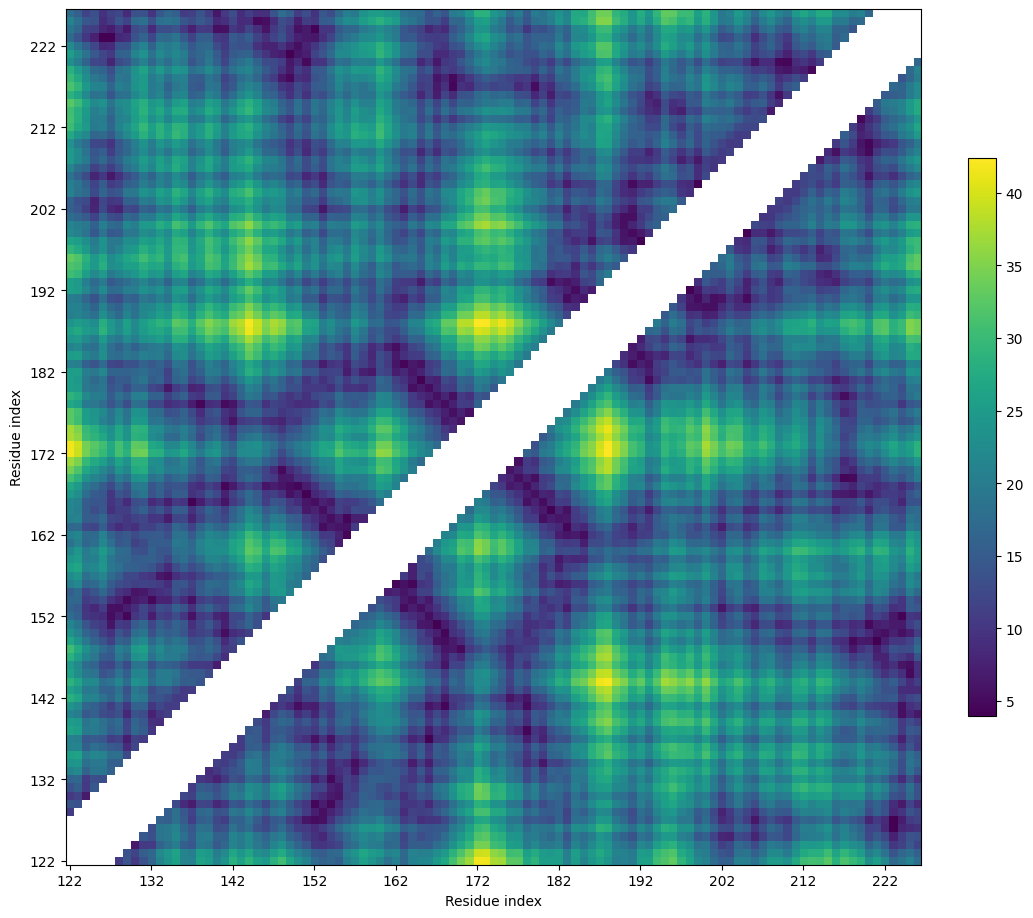

In [25]:
current_cmap = copy.copy(matplotlib.cm.get_cmap())
current_cmap.set_bad(color='white')

fig, ax = plt.subplots(figsize=(12, 12))
im = ax.imshow(dist_matrix, cmap=current_cmap, origin='lower')

# подписи осей
step = 10
ax.set_xticks(range(0, len(residue_ids), step))
ax.set_yticks(range(0, len(residue_ids), step))

ax.set_xticklabels(residue_ids[::step])
ax.set_yticklabels(residue_ids[::step])

ax.set_xlabel("Residue index")
ax.set_ylabel("Residue index")
fig.colorbar(im, fraction=0.03, pad=0.05)
plt.savefig(path + '/figures/ca_distances_{}.png'.format(pdb_id), dpi=300, bbox_inches='tight')

# Ex. 8: Contact map of aforementioned pic w 5 Armstrong dist threshold

In [26]:
# Calculate the contact map based on a distace threshold 8 Angstrom
# Create a mask of the distance matrix based on a filter and cast to float
contact_map = (dist_matrix[:] < 5).astype(float)
contact_map

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

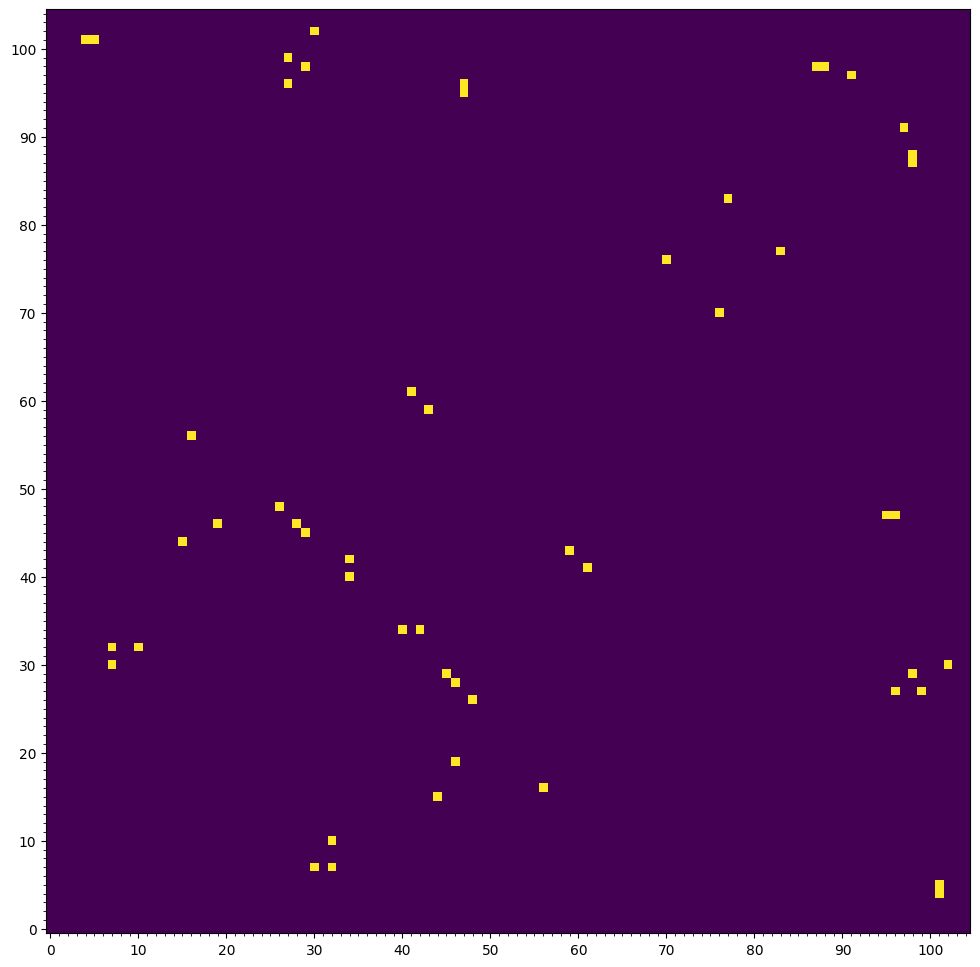

In [27]:
# Plot contact map
fig, ax = plt.subplots(figsize=(12, 12))
im = ax.imshow(contact_map, origin='lower')

# Set ticks
ax.xaxis.set_major_locator(MultipleLocator(10))
ax.xaxis.set_minor_locator(AutoMinorLocator(10))
ax.yaxis.set_major_locator(MultipleLocator(10))
ax.yaxis.set_minor_locator(AutoMinorLocator(10))

plt.savefig(path + '/figures/ca_contacts_{}.png'.format(pdb_id), dpi=300, bbox_inches='tight')

# Ex. 9: Intervals

Structure exists: 'drive/MyDrive/Colab Notebooks/Structural Biology/data/pdb/pdb1lkk.ent' 


/tmp/ipykernel_20415/919628277.py:109: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  current_cmap = copy.copy(matplotlib.cm.get_cmap())


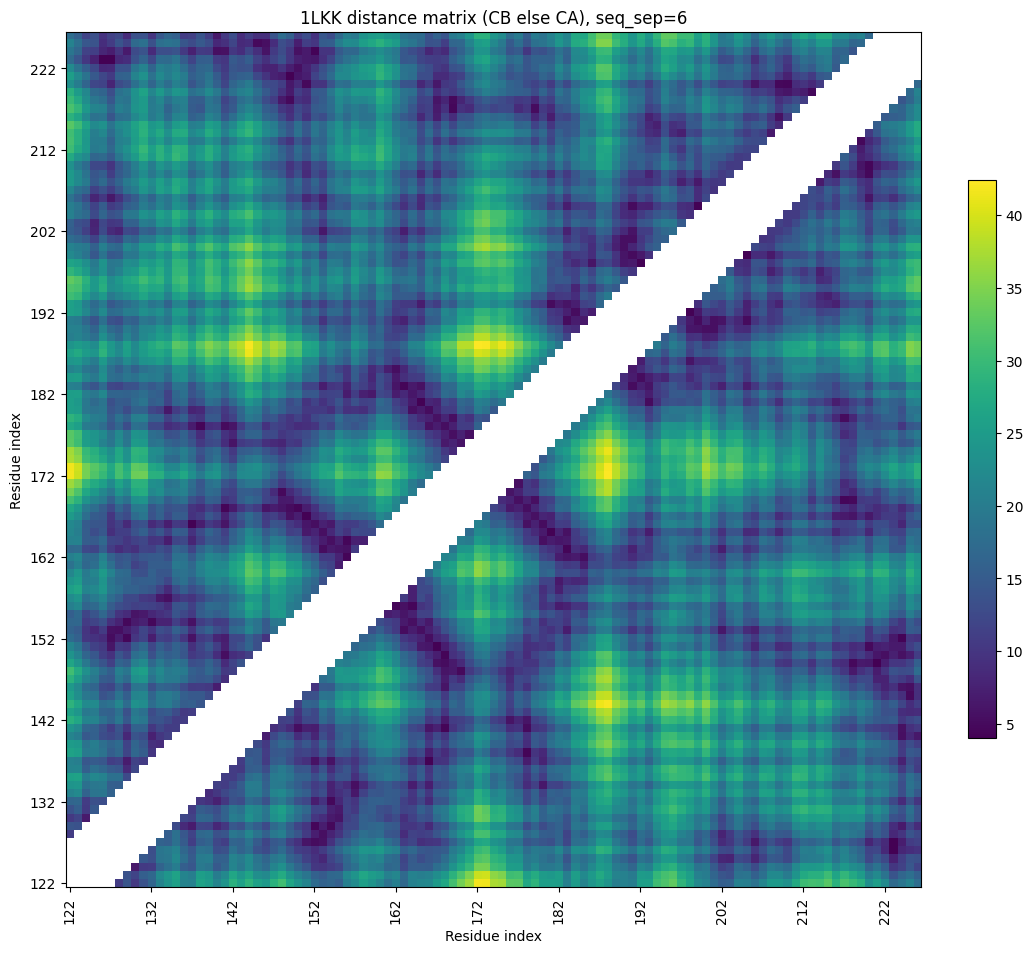

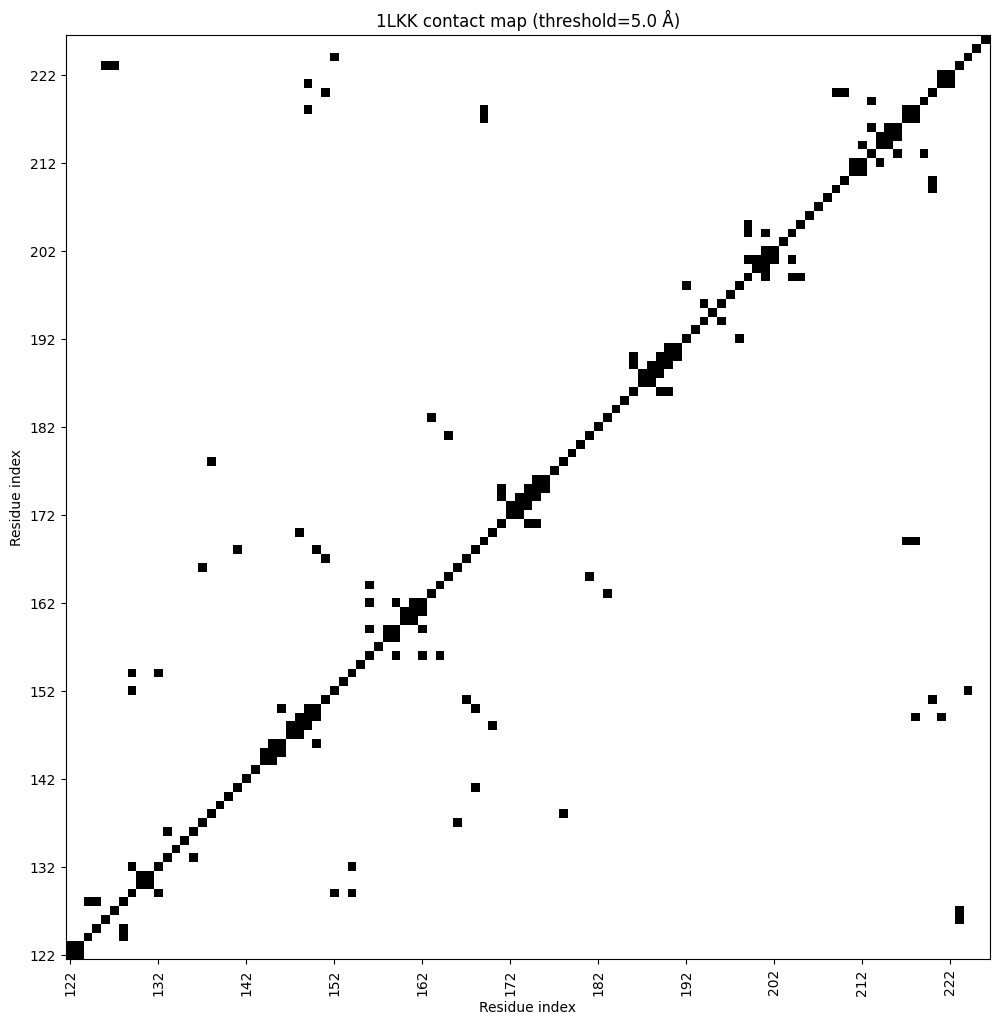

  sequence_separation_range  n_contacts
0                     [0,6]         197
1                    [7,12]           6
2                   [13,24]          14
3                    [25,∞]          24

Total contacts: 241
Sum of ranges: 241
Check passed: True


In [28]:
import os
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
from Bio.PDB import PDBList, PDBParser

# =========================
# Parameters
# =========================
pdb_id = '1lkk'
chain_id = 'A'
sequence_separation = 6          # для heatmap
contact_threshold = 5.0          # Å для contact map / counting
tick_step = 10

# =========================
# Helper functions
# =========================
def get_rep_atom(residue):
    """
    Use CB if present, otherwise CA only for that residue.
    """
    if "CB" in residue:
        return residue["CB"]
    elif "CA" in residue:
        return residue["CA"]
    else:
        return None

def get_distance_matrix(residues, seq_sep=0):
    """
    Distance matrix using CB when available for each residue individually,
    otherwise CA for that residue only.
    Pairs with |i-j| < seq_sep are set to NaN.
    """
    n = len(residues)
    dist = np.full((n, n), np.nan, dtype=float)

    rep_atoms = [get_rep_atom(res) for res in residues]

    for i, residue1 in enumerate(residues):
        atom1 = rep_atoms[i]
        if atom1 is None:
            continue

        for j, residue2 in enumerate(residues):
            if abs(i - j) < seq_sep:
                continue

            atom2 = rep_atoms[j]
            if atom2 is None:
                continue

            dist[i, j] = atom1 - atom2

    return dist

def make_contact_map(dist_matrix, threshold=5.0):
    """
    Binary contact map: 1 if distance <= threshold, else 0.
    NaN values become 0.
    """
    return np.where(np.isfinite(dist_matrix) & (dist_matrix <= threshold), 1, 0).astype(int)

def count_contacts_by_sep_ranges(contact_map):
    """
    Count contacts in sequence-separation intervals:
    [0,6], [7,12], [13,24], [25,∞]

    Uses the FULL contact map, including main diagonal.
    Counts all matrix elements, so sum of bins = total contacts.
    """
    n = contact_map.shape[0]
    sep = np.abs(np.subtract.outer(np.arange(n), np.arange(n)))

    masks = {
        "[0,6]":   (sep >= 0) & (sep <= 6),
        "[7,12]":  (sep >= 7) & (sep <= 12),
        "[13,24]": (sep >= 13) & (sep <= 24),
        "[25,∞]":  (sep >= 25),
    }

    counts = {label: int(np.sum(contact_map[mask])) for label, mask in masks.items()}
    counts["total_contacts"] = int(np.sum(contact_map))
    counts["sum_of_ranges"] = counts["[0,6]"] + counts["[7,12]"] + counts["[13,24]"] + counts["[25,∞]"]

    return counts

# =========================
# Load structure
# =========================
pdbl = PDBList()
pdbl.retrieve_pdb_file(pdb_id, pdir=os.path.join(path, "pdb"), file_format='pdb')

pdb_file = os.path.join(path, "pdb", f"pdb{pdb_id}.ent")
structure = PDBParser(QUIET=True).get_structure(pdb_id, pdb_file)

# select chain A of first model (0), exclude hetero and water
selected_residues = [residue for residue in structure[0][chain_id] if residue.id[0] == " "]
residue_ids = [res.id[1] for res in selected_residues]

# =========================
# 1) Distance matrix for plotting with seq_separation = 6
# =========================
dist_matrix_plot = get_distance_matrix(selected_residues, seq_sep=sequence_separation)

current_cmap = copy.copy(matplotlib.cm.get_cmap())
current_cmap.set_bad(color='white')

fig, ax = plt.subplots(figsize=(12, 12))
im = ax.imshow(dist_matrix_plot, cmap=current_cmap, origin='lower')

ax.set_xticks(range(0, len(residue_ids), tick_step))
ax.set_yticks(range(0, len(residue_ids), tick_step))
ax.set_xticklabels(residue_ids[::tick_step], rotation=90)
ax.set_yticklabels(residue_ids[::tick_step])

ax.set_xlabel("Residue index")
ax.set_ylabel("Residue index")
ax.set_title(f"{pdb_id.upper()} distance matrix (CB else CA), seq_sep={sequence_separation}")

fig.colorbar(im, fraction=0.03, pad=0.05)
plt.savefig(os.path.join(path, 'figures', f'cb_ca_distances_{pdb_id}.png'),
            dpi=300, bbox_inches='tight')
plt.show()

# =========================
# 2) FULL distance matrix for counting contacts by sequence-separation ranges
#    seq_sep must be 0 here, otherwise [0,6] cannot be counted correctly
# =========================
dist_matrix_all = get_distance_matrix(selected_residues, seq_sep=0)
contact_map_all = make_contact_map(dist_matrix_all, threshold=contact_threshold)

# Optional: plot contact map
fig, ax = plt.subplots(figsize=(12, 12))
im = ax.imshow(contact_map_all, cmap='Greys', origin='lower')

ax.set_xticks(range(0, len(residue_ids), tick_step))
ax.set_yticks(range(0, len(residue_ids), tick_step))
ax.set_xticklabels(residue_ids[::tick_step], rotation=90)
ax.set_yticklabels(residue_ids[::tick_step])

ax.set_xlabel("Residue index")
ax.set_ylabel("Residue index")
ax.set_title(f"{pdb_id.upper()} contact map (threshold={contact_threshold} Å)")

plt.savefig(os.path.join(path, 'figures', f'contact_map_{pdb_id}.png'),
            dpi=300, bbox_inches='tight')
plt.show()

# =========================
# 3) Count contacts in the requested sequence-separation ranges
# =========================
counts = count_contacts_by_sep_ranges(contact_map_all)

counts_df = pd.DataFrame({
    "sequence_separation_range": ["[0,6]", "[7,12]", "[13,24]", "[25,∞]"],
    "n_contacts": [
        counts["[0,6]"],
        counts["[7,12]"],
        counts["[13,24]"],
        counts["[25,∞]"],
    ]
})

print(counts_df)
print("\nTotal contacts:", counts["total_contacts"])
print("Sum of ranges:", counts["sum_of_ranges"])
print("Check passed:", counts["total_contacts"] == counts["sum_of_ranges"])

# Ex.10: Ramachandran

In [35]:
# Calculate PSI and PHI
ppb = PPBuilder()
rama = {}  # { chain : [[residue_1, ...], [phi_residue_1, ...], [psi_residue_2, ...] ] }
for model in structure:
    for chain in model:
        for pp in ppb.build_peptides(chain):

            phi_psi = pp.get_phi_psi_list()  # [(phi_residue_1, psi_residue_1), ...]
            for i, residue in enumerate(pp):
               # print(model, chain, i, residue, phi_psi[i])

                # Convert radians to degrees and remove first and last value that are None
                if phi_psi[i][0] is not None and phi_psi[i][1] is not None:
                    rama.setdefault(chain.id, [[], [], []])
                    rama[chain.id][0].append(residue)
                    rama[chain.id][1].append(math.degrees(phi_psi[i][0]))  # phi
                    rama[chain.id][2].append(math.degrees(phi_psi[i][1]))  # psi


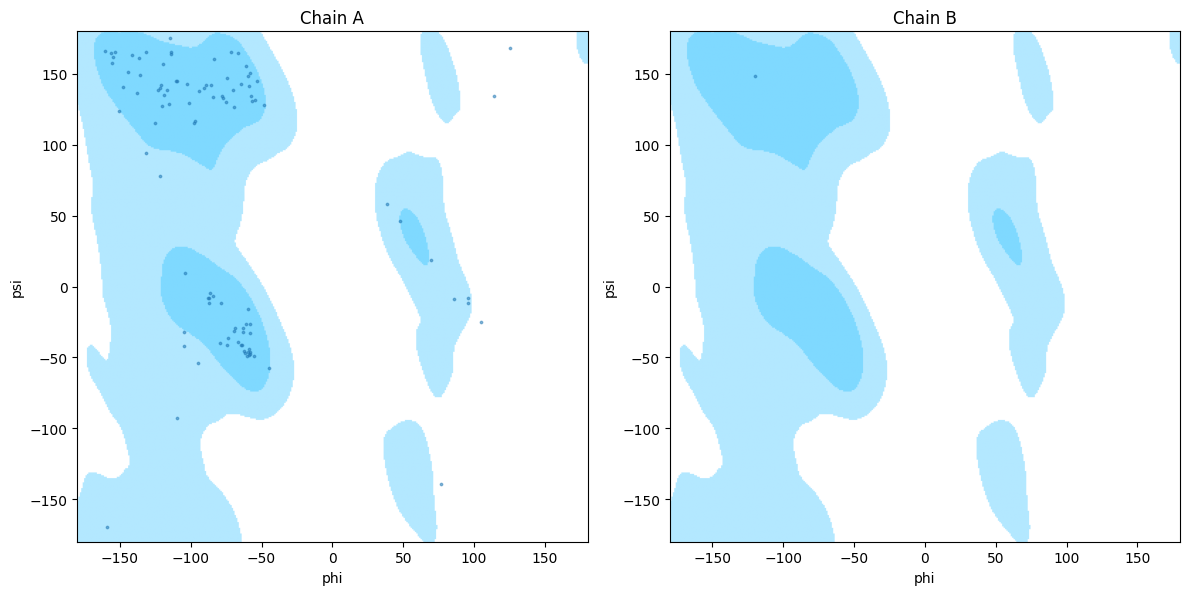

In [38]:
# Ramachandran regions
# 2 = 90%, 1 = 60%
regions_matrix = []
with open(path + "/ramachandran.dat") as f:
    for line in f:
        if line:
            regions_matrix.append([int(ele) for ele in line.strip().split()])

# Plot Ramachandran regions
cmap = mplcolors.ListedColormap(['#FFFFFF', '#B3E8FF', '#7FD9FF'])

f, axes = plt.subplots(1, len(rama), figsize=(12, 12))
axes = np.array(axes).reshape(-1)  # Hack to give consistency for single/multiple suplots (-1 force reshape to infer dimensions)
for ax, chain_id in zip(axes, rama):

    # Plot regions (60 percentile & 90 percentile)
    im = ax.imshow(regions_matrix, cmap=cmap, extent=(-180, 180, -180, 180))

    # Plot points
    ax.scatter(rama[chain_id][1], rama[chain_id][2], s=3, alpha=0.5)

    ax.set_xlabel('phi')
    ax.set_ylabel('psi')
    ax.set_title('Chain {}'.format(chain_id))

plt.tight_layout()  # Remove figure padding
plt.savefig(path +'/figures/ramachandran_regions.png', dpi=300, bbox_inches='tight')

In [42]:
import pandas as pd

def is_allowed_ramachandran(phi, psi):
    """
    Simple allowed regions for a generic Ramachandran plot.
    You can tune boundaries if your practical used slightly different ones.
    """
    return (
        (-160 <= phi <= -30 and -80 <= psi <= 50) or    # right-handed alpha helix
        (-180 <= phi <= -60 and 90 <= psi <= 180) or    # beta sheet
        (30 <= phi <= 90 and 0 <= psi <= 90)            # left-handed alpha helix
    )

rama_outliers = {}

for chain_id, values in rama.items():
    residues = values[0]
    phi_list = values[1]
    psi_list = values[2]

    rama_outliers[chain_id] = []

    for residue, phi, psi in zip(residues, phi_list, psi_list):
        if not is_allowed_ramachandran(phi, psi):
            rama_outliers[chain_id].append((residue, phi, psi))

# print summary
for chain_id, outliers in rama_outliers.items():
    print(f"Chain {chain_id}: {len(outliers)} outliers")

Chain A: 18 outliers
Chain B: 0 outliers
